In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Notebook may start in notebooks/ or in the project root
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data"

# Use the real sample if it exists, otherwise the FAKE toy file
real = DATA / "sample_flights.parquet"
path = real if real.exists() else DATA / "toy_flights.parquet"
USING_TOY = not real.exists()

df = pd.read_parquet(path)
print("Loaded:", path.name, "| rows:", len(df))
if USING_TOY:
    print("WARNING: this is FAKE toy data. Charts mean nothing.")
df.head()

Loaded: sample_flights.parquet | rows: 20000


,flight_date,tail_number,route,dep_hour,delayed,delay_min,airline,origin,dest,month,...,o_cloud_cover,o_wind_speed_10m,o_wind_gusts_10m,o_weather_code,d_temperature_2m,d_precipitation,d_cloud_cover,d_wind_speed_10m,d_wind_gusts_10m,d_weather_code
341450,2023-10-30,N584UW,DFW_SFO,8,0,7.0,AA,DFW,SFO,10,...,9,24.0,41.0,0,15.1,0.0,0.0,7.9,19.8,0.0
40337,2023-02-10,N553UW,DEN_MIA,11,1,66.0,AA,DEN,MIA,2,...,0,13.0,21.2,0,26.5,0.0,0.0,15.0,33.5,0.0
406202,2023-11-02,N7844A,DEN_ORD,16,0,10.0,WN,DEN,ORD,11,...,56,9.4,22.7,2,7.8,0.0,100.0,15.9,28.1,3.0
248902,2023-07-03,N37267,SFO_DEN,20,1,22.0,UA,SFO,DEN,7,...,89,15.1,33.5,3,20.6,0.0,59.0,5.1,9.7,2.0
34621,2023-02-07,N117AN,JFK_LAX,19,0,0.0,AA,JFK,LAX,2,...,100,19.9,32.0,3,10.0,0.0,80.0,11.5,14.4,3.0


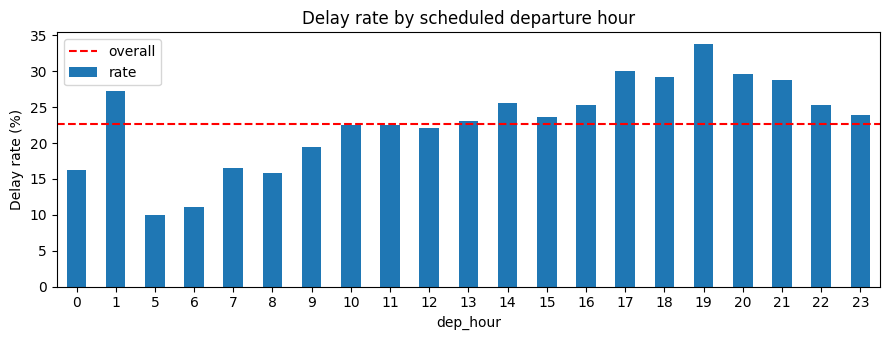

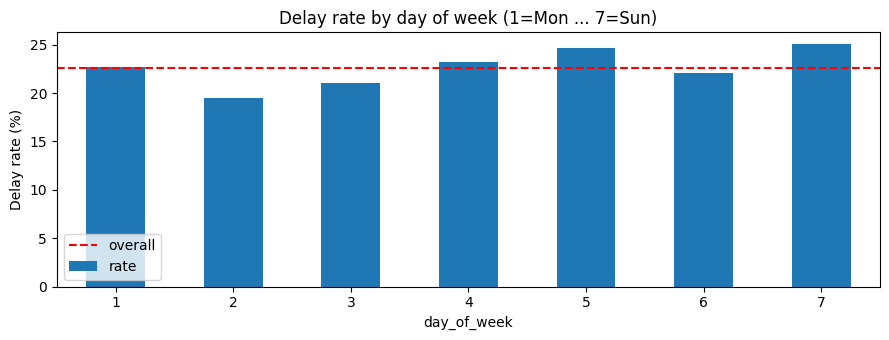

,rate,n
dep_hour,,
0,0.162500,80
1,0.272727,22
5,0.100402,498
6,0.110877,1425
7,0.165089,1690
8,0.158283,1491
9,0.193858,1042
10,0.224832,1192
11,0.225044,1142


In [2]:
def rate_plot(df, col, title, rot=0):
    g = df.groupby(col)["delayed"].agg(rate="mean", n="size")
    ax = g["rate"].mul(100).plot(kind="bar", figsize=(9, 3.5), rot=rot)
    ax.set_title(title + (" [TOY DATA]" if USING_TOY else ""))
    ax.set_ylabel("Delay rate (%)")
    ax.axhline(df["delayed"].mean() * 100, color="red", ls="--", label="overall")
    ax.legend()
    plt.tight_layout()
    plt.show()
    return g

by_hour = rate_plot(df, "dep_hour", "Delay rate by scheduled departure hour")
by_dow = rate_plot(df, "day_of_week", "Delay rate by day of week (1=Mon ... 7=Sun)")
by_hour

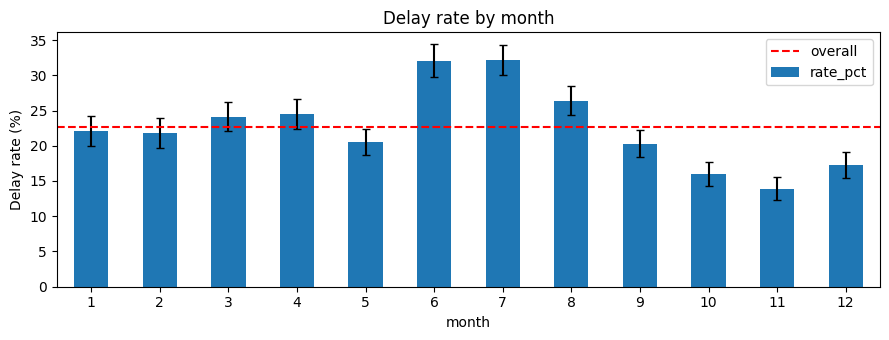

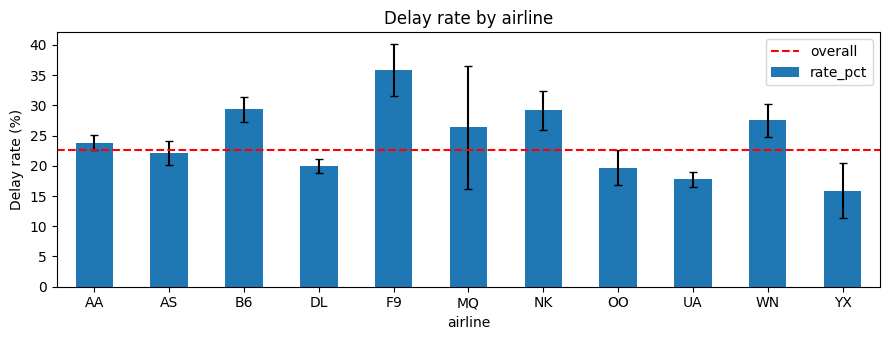

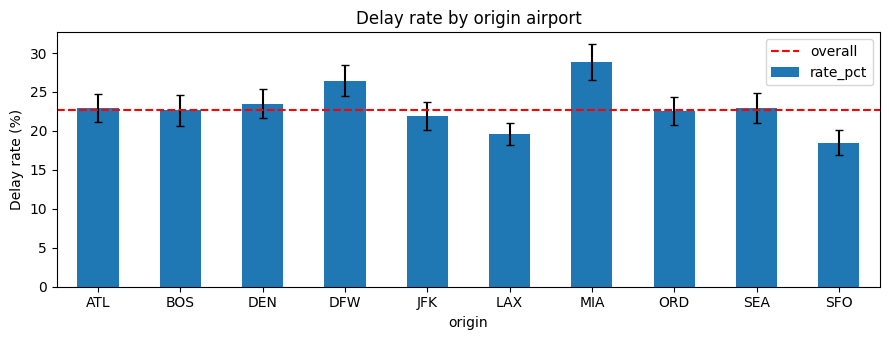

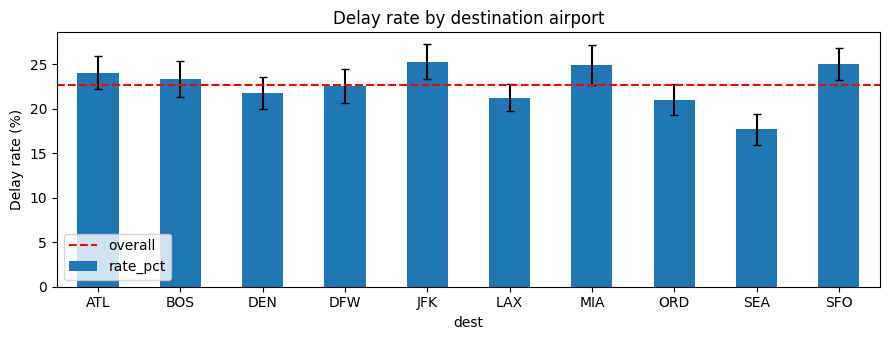

,n,rate_pct,ci95_pct
airline,,,
AA,4794,23.8,1.2
AS,1678,22.1,2.0
B6,1903,29.3,2.0
DL,4618,19.9,1.2
F9,494,35.8,4.2
MQ,72,26.4,10.2
NK,755,29.1,3.2
OO,761,19.7,2.8
UA,3611,17.8,1.2


In [3]:
import numpy as np

def rate_table(df, col):
    g = df.groupby(col)["delayed"].agg(rate="mean", n="size")
    g["rate_pct"] = g["rate"] * 100
    # 95% margin of error for a proportion: 1.96 * sqrt(p(1-p)/n)
    g["ci95_pct"] = 1.96 * np.sqrt(g["rate"] * (1 - g["rate"]) / g["n"]) * 100
    return g

def bar_rate(g, title, rot=0, figsize=(9, 3.5)):
    ax = g["rate_pct"].plot(kind="bar", yerr=g["ci95_pct"], capsize=3,
                            figsize=figsize, rot=rot)
    ax.axhline(df["delayed"].mean() * 100, color="red", ls="--", label="overall")
    ax.set_title(title + (" [TOY DATA]" if USING_TOY else ""))
    ax.set_ylabel("Delay rate (%)")
    ax.legend()
    plt.tight_layout()
    plt.show()

by_month = rate_table(df, "month")
by_airline = rate_table(df, "airline")
by_origin = rate_table(df, "origin")
by_dest = rate_table(df, "dest")

bar_rate(by_month, "Delay rate by month")
bar_rate(by_airline, "Delay rate by airline")
bar_rate(by_origin, "Delay rate by origin airport")
bar_rate(by_dest, "Delay rate by destination airport")
by_airline[["n", "rate_pct", "ci95_pct"]].round(1)

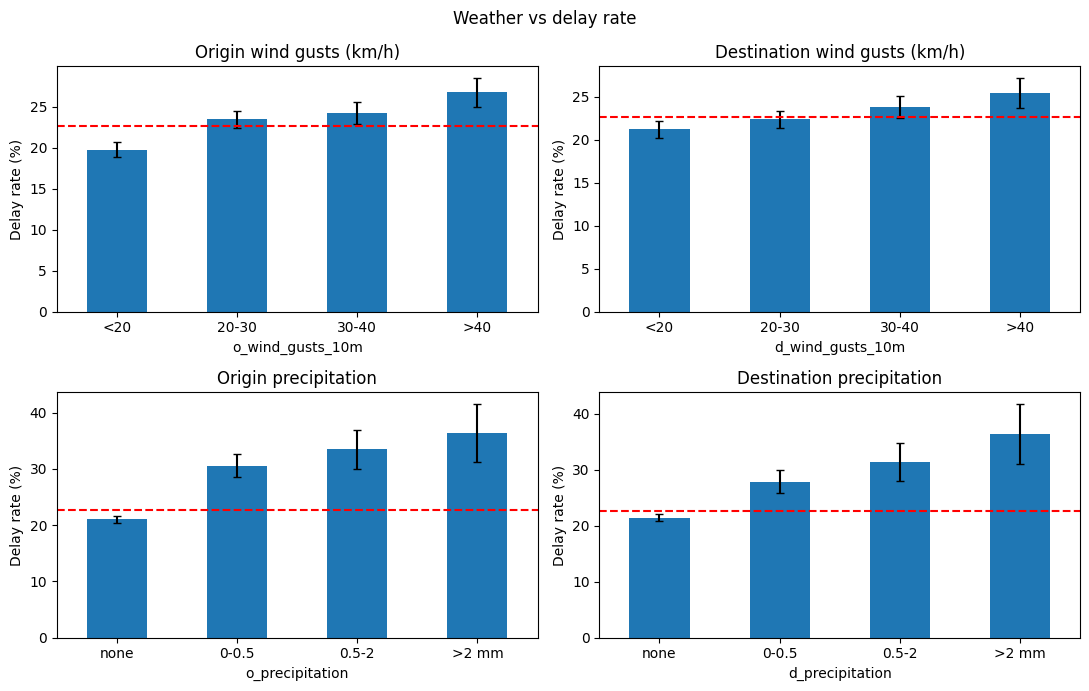

,rate,n,rate_pct,ci95_pct
o_wind_gusts_10m,,,,
<20,0.197271,7330,19.727149,0.911005
20-30,0.234591,6279,23.459150,1.048126
30-40,0.241747,3938,24.174708,1.337229
>40,0.267428,2453,26.742764,1.751603


In [4]:
def weather_plot(ax, col, bins, labels, title):
    cat = pd.cut(df[col], bins=bins, labels=labels, include_lowest=True)
    g = df.groupby(cat, observed=True)["delayed"].agg(rate="mean", n="size")
    g["rate_pct"] = g["rate"] * 100
    g["ci95_pct"] = 1.96 * np.sqrt(g["rate"] * (1 - g["rate"]) / g["n"]) * 100
    g["rate_pct"].plot(kind="bar", yerr=g["ci95_pct"], capsize=3, ax=ax, rot=0)
    ax.axhline(df["delayed"].mean() * 100, color="red", ls="--")
    ax.set_title(title)
    ax.set_ylabel("Delay rate (%)")
    return g

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
gust_bins = [-0.1, 20, 30, 40, 200]
gust_labels = ["<20", "20-30", "30-40", ">40"]
rain_bins = [-0.1, 0, 0.5, 2, 1000]
rain_labels = ["none", "0-0.5", "0.5-2", ">2 mm"]

w1 = weather_plot(axes[0, 0], "o_wind_gusts_10m", gust_bins, gust_labels, "Origin wind gusts (km/h)")
w2 = weather_plot(axes[0, 1], "d_wind_gusts_10m", gust_bins, gust_labels, "Destination wind gusts (km/h)")
w3 = weather_plot(axes[1, 0], "o_precipitation", rain_bins, rain_labels, "Origin precipitation")
w4 = weather_plot(axes[1, 1], "d_precipitation", rain_bins, rain_labels, "Destination precipitation")
plt.suptitle("Weather vs delay rate" + (" [TOY DATA]" if USING_TOY else ""))
plt.tight_layout()
plt.show()
w1

In [5]:
print("Duplicate rows:", df.duplicated().sum())
print("Holiday flights:", int(df["is_holiday"].sum()), f"({df['is_holiday'].mean()*100:.1f}%)")
print("Share of flights with delay_min == 0:", f"{(df['delay_min'] == 0).mean()*100:.1f}%")
print("Share capped at 300:", f"{(df['delay_min'] == 300).mean()*100:.2f}%")
print()
print(df["delay_min"].describe().round(1))
print()
print(rate_table(df, "is_holiday")[["n", "rate_pct"]].round(1))
print()
print(df[["dep_hour", "distance", "sched_duration", "origin_dep_count"]].describe().round(1))

Duplicate rows: 0
Holiday flights: 695 (3.5%)
Share of flights with delay_min == 0: 60.7%
Share capped at 300: 0.57%

count    20000.0
mean        16.2
std         40.9
min          0.0
25%          0.0
50%          0.0
75%         13.0
max        300.0
Name: delay_min, dtype: float64

                n  rate_pct
is_holiday                 
0           19305      22.8
1             695      18.7

       dep_hour  distance  sched_duration  origin_dep_count
count   20000.0   20000.0         20000.0           20000.0
mean       13.1    1321.5           210.2              34.2
std         5.2     711.1            87.0              17.9
min         0.0     187.0            65.0               1.0
25%         8.0     760.0           145.0              21.0
50%        13.0    1089.0           184.5              30.0
75%        17.0    1754.0           273.0              45.0
max        23.0    2724.0           433.0              92.0


In [6]:
from sklearn.metrics import (roc_curve, roc_auc_score, precision_recall_curve,
                            average_precision_score, mean_absolute_error,
                            mean_squared_error)
import numpy as np

tp = pd.read_parquet(DATA / "test_predictions.parquet")
tp["flight_date"] = pd.to_datetime(tp["flight_date"])

need = {"flight_date", "airline", "origin", "dest", "delayed",
        "delay_min", "proba_raw", "proba", "pred_minutes"}
print("Missing columns:", need - set(tp.columns) or "none")
print("Rows:", len(tp))
print("Months present:\n", tp["flight_date"].dt.month.value_counts().sort_index())
print("Actual delay rate: %.1f%%" % (tp["delayed"].mean() * 100))
print("Mean calibrated proba: %.1f%%" % (tp["proba"].mean() * 100))
print("Mean predicted minutes: %.1f | mean actual minutes: %.1f"
    % (tp["pred_minutes"].mean(), tp["delay_min"].mean()))

Missing columns: none
Rows: 73099
Months present:
 flight_date
11    36580
12    36519
Name: count, dtype: int64
Actual delay rate: 15.3%
Mean calibrated proba: 16.1%
Mean predicted minutes: 13.8 | mean actual minutes: 9.7


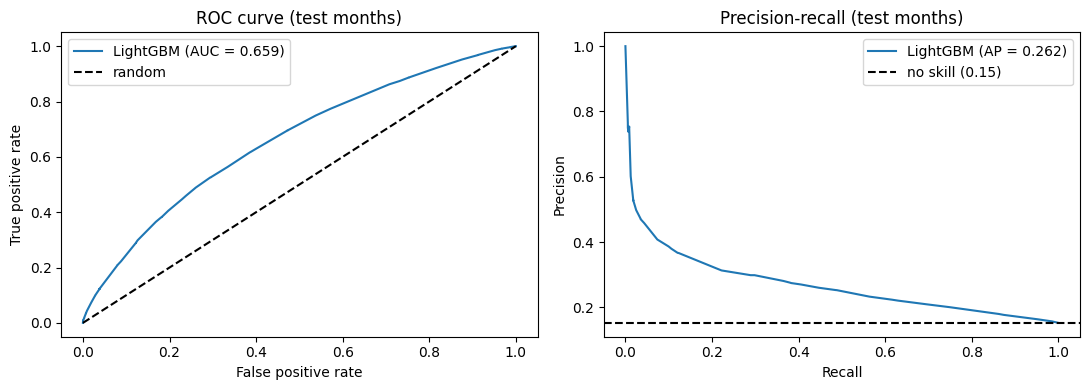

ROC-AUC = 0.659 | Average precision = 0.262


In [7]:
y, p = tp["delayed"], tp["proba"]
auc = roc_auc_score(y, p)
ap = average_precision_score(y, p)

fpr, tpr, _ = roc_curve(y, p)
prec, rec, _ = precision_recall_curve(y, p)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(fpr, tpr, label=f"LightGBM (AUC = {auc:.3f})")
ax[0].plot([0, 1], [0, 1], "k--", label="random")
ax[0].set(title="ROC curve (test months)", xlabel="False positive rate",
          ylabel="True positive rate")
ax[0].legend()

ax[1].plot(rec, prec, label=f"LightGBM (AP = {ap:.3f})")
ax[1].axhline(y.mean(), color="k", ls="--", label=f"no skill ({y.mean():.2f})")
ax[1].set(title="Precision-recall (test months)", xlabel="Recall", ylabel="Precision")
ax[1].legend()
plt.tight_layout(); plt.show()
print(f"ROC-AUC = {auc:.3f} | Average precision = {ap:.3f}")

Model: MAE 16.34, RMSE 29.96
Naive mean (18.3 min): MAE 20.22, RMSE 31.09


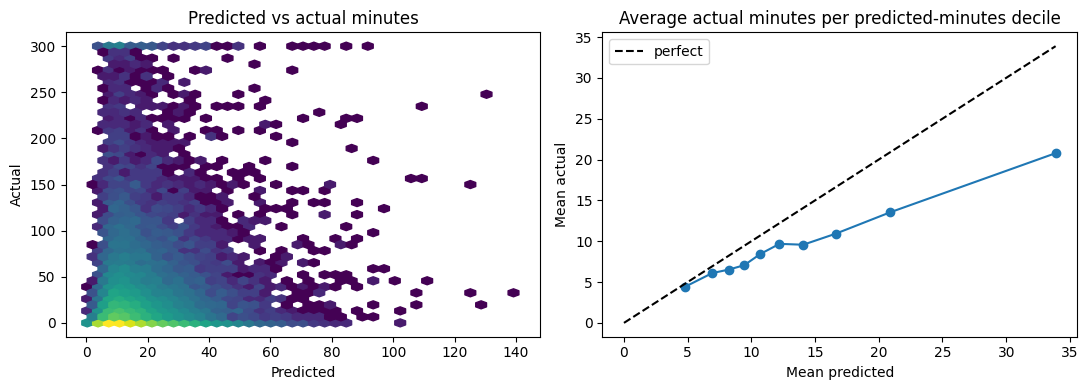

In [8]:
s = pd.read_parquet(DATA / "sample_flights.parquet")
train_mean = s.loc[s["month"].between(1, 9), "delay_min"].mean()  # approx: from the SAMPLE

mae = mean_absolute_error(tp["delay_min"], tp["pred_minutes"])
rmse = np.sqrt(mean_squared_error(tp["delay_min"], tp["pred_minutes"]))
naive = np.full(len(tp), train_mean)
mae_n = mean_absolute_error(tp["delay_min"], naive)
rmse_n = np.sqrt(mean_squared_error(tp["delay_min"], naive))
print(f"Model: MAE {mae:.2f}, RMSE {rmse:.2f}")
print(f"Naive mean ({train_mean:.1f} min): MAE {mae_n:.2f}, RMSE {rmse_n:.2f}")

tp["pred_bin"] = pd.qcut(tp["pred_minutes"], 10, duplicates="drop")
g = tp.groupby("pred_bin", observed=True)[["pred_minutes", "delay_min"]].mean()

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hexbin(tp["pred_minutes"], tp["delay_min"], gridsize=40, bins="log", mincnt=1)
ax[0].set(title="Predicted vs actual minutes", xlabel="Predicted", ylabel="Actual")
ax[1].plot(g["pred_minutes"], g["delay_min"], "o-")
lim = max(g.max().max(), 1)
ax[1].plot([0, lim], [0, lim], "k--", label="perfect")
ax[1].set(title="Average actual minutes per predicted-minutes decile",
          xlabel="Mean predicted", ylabel="Mean actual")
ax[1].legend()
plt.tight_layout(); plt.show()

In [9]:
zero_pred = np.zeros(len(tp))
median_pred = np.full(len(tp), s.loc[s["month"].between(1, 9), "delay_min"].median())
for name, pred in [("Model", tp["pred_minutes"]),
                   ("Naive mean (train, approx.)", naive),
                   ("Predict 0 for all", zero_pred),
                   ("Predict train median", median_pred)]:
    m = mean_absolute_error(tp["delay_min"], pred)
    r = np.sqrt(mean_squared_error(tp["delay_min"], pred))
    print(f"{name:30s} MAE {m:6.2f}   RMSE {r:6.2f}")
print("Bias (pred - actual):", round((tp["pred_minutes"] - tp["delay_min"]).mean(), 2))

Model                          MAE  16.34   RMSE  29.96
Naive mean (train, approx.)    MAE  20.22   RMSE  31.09
Predict 0 for all              MAE   9.70   RMSE  31.42
Predict train median           MAE   9.70   RMSE  31.42
Bias (pred - actual): 4.07


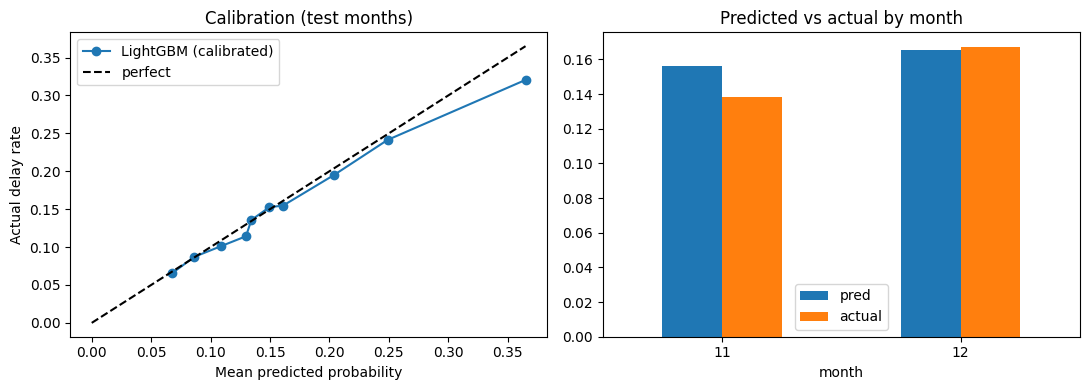

,pred,actual,n
p_bin,,,
"(-0.001, 0.0788]",0.067,0.065,8222
"(0.0788, 0.0891]",0.086,0.087,8372
"(0.0891, 0.111]",0.109,0.101,12448
"(0.111, 0.13]",0.130,0.114,2398
"(0.13, 0.138]",0.134,0.136,9811
"(0.138, 0.152]",0.149,0.153,4856
"(0.152, 0.169]",0.161,0.155,5454
"(0.169, 0.235]",0.204,0.195,7033
"(0.235, 0.26]",0.249,0.241,7222


In [10]:
tp["p_bin"] = pd.qcut(tp["proba"], 10, duplicates="drop")
cal = tp.groupby("p_bin", observed=True).agg(pred=("proba", "mean"),
                                             actual=("delayed", "mean"),
                                             n=("delayed", "size"))
tp["month"] = tp["flight_date"].dt.month
by_m = tp.groupby("month").agg(pred=("proba", "mean"), actual=("delayed", "mean"))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(cal["pred"], cal["actual"], "o-", label="LightGBM (calibrated)")
lim = cal[["pred", "actual"]].max().max()
ax[0].plot([0, lim], [0, lim], "k--", label="perfect")
ax[0].set(title="Calibration (test months)", xlabel="Mean predicted probability",
        ylabel="Actual delay rate")
ax[0].legend()
by_m.plot(kind="bar", ax=ax[1], rot=0, title="Predicted vs actual by month")
plt.tight_layout(); plt.show()
cal.round(3)

In [ ]:
from ml.community_model import evaluate_community_model

comparison = pd.read_csv(DATA / "comparison_table.csv", index_col=0)
community = evaluate_community_model(df)
comparison.loc["Community model (not comparable)"] = np.nan

display(comparison.round(3))
print("Community model reason:", community["reason"])

In [ ]:
import joblib
import shap
from config import MODEL_DIR
from ml.explain import _test_sample, build_explainer

clf = joblib.load(MODEL_DIR / "clf.joblib")
X_shap, shap_meta = _test_sample(n=2000)
shap_explainer = build_explainer(clf)
shap_values = shap_explainer.shap_values(X_shap)
shap.summary_plot(shap_values, X_shap, max_display=10, show=False)
plt.title("SHAP summary: test flights")
plt.tight_layout()
plt.show()

In [ ]:
import sys
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from ml.risk_cutoffs import suggest_cutoffs, _level_rows

res = suggest_cutoffs(tp["delayed"], tp["proba"])
print("Metric-only suggested cutoffs:", res["low_max"], res["high_min"], "|", res["note"])

print("\nMetric-only suggestion:")
print(pd.DataFrame(_level_rows(tp["delayed"], tp["proba"],
                               res["low_max"], res["high_min"])).round(3))
print("\nSelected cutoffs (0.15 / 0.30):")
print(pd.DataFrame(_level_rows(tp["delayed"], tp["proba"], 0.15, 0.30)).round(3))
print("\nThe selected cutoffs retain a broader Low/Medium/High distribution;")
print("the metric-only suggestion places about 93% of flights in Medium.")